In [1]:
#from videoextract import LaserFlexInputVideo, LaserFlexWrapOptions, LaserFlexProcessOptions, LaserFlexLineData, LaserFlexLineToImageOptions, LaserFlexOutput
from videoextract import LaserReflexData
from videoextract_notebook_ui import rectify_image_ui, line2image_ui, show_output_ui

laserFlexData = LaserReflexData(r"D:\Documents_large\laserflex\4samples\\")
laserFlexData.load()
%matplotlib widget


OpenCV Version: 4.7.0
Dateipfad: D:\Documents_large\laserflex\4samples\input.mp4
Datei existiert: True
Video erfolgreich geöffnet!
Backend: FFMPEG
FPS: 29.84088529927635
Frames: 23588
Auflösung: 1280 x 720


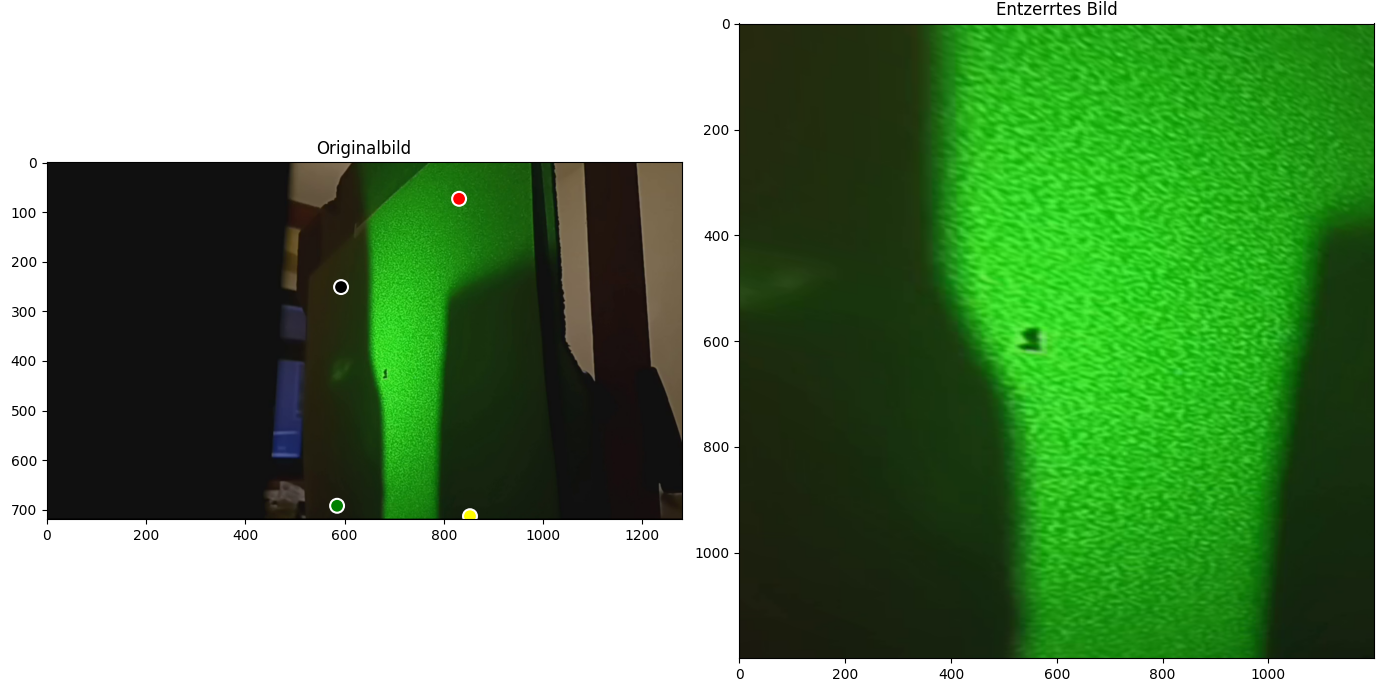

einstellen...


In [5]:
laserFlexData.wrapOptions.outputWidth = 1200
laserFlexData.wrapOptions.outputHeight = 1200
rectify_image_ui(laserFlexData)
print("einstellen...");

In [3]:
laserFlexData.processOptions.angleResolutionX = 100
laserFlexData.processOptions.angleResolutionY = 100
laserFlexData.processOptions.save()

laserFlexData.process_video()
laserFlexData.lineData.save()


Verarbeite Frames:   0%|          | 0/23588 [00:00<?, ?it/s]

Verarbeite Frames:   0%|          | 0/23588 [00:00<?, ?it/s]

einstellen...


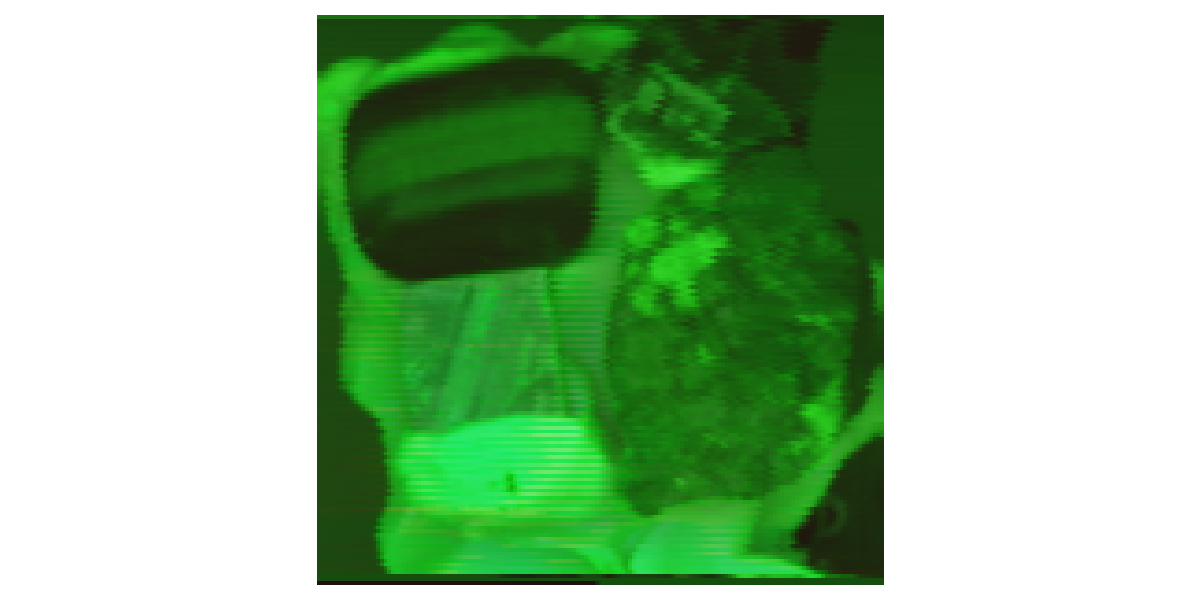

In [4]:
line2image_ui(laserFlexData)

print("einstellen...");

In [22]:
laserFlexData.line_to_image()
laserFlexData.output.save();

Features rekonstruieren:   0%|          | 0/5 [00:00<?, ?it/s]

Winkelbilder rekonstruieren:   0%|          | 0/10000 [00:00<?, ?it/s]

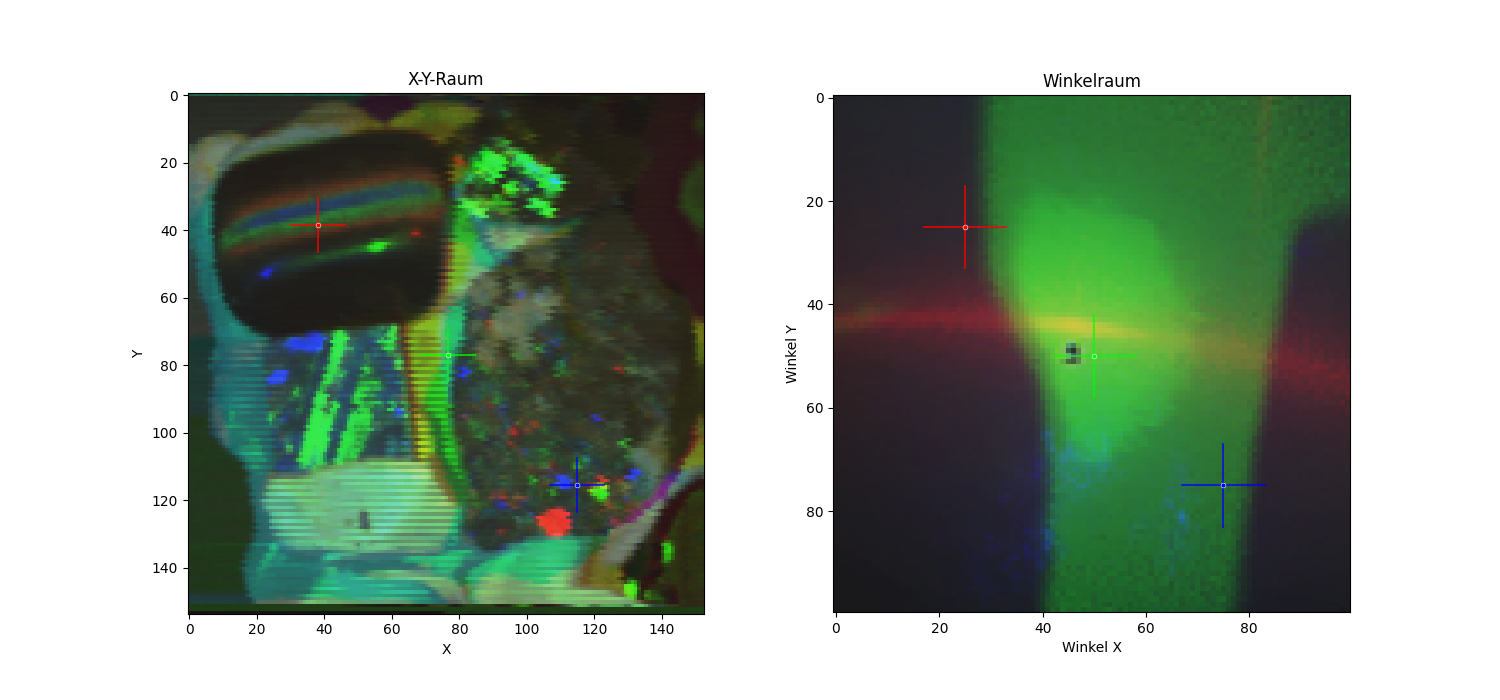

In [23]:
show_output_ui(laserFlexData)

In [67]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

def show_features(features, means):
    """
    features: Array mit Shape (5, height, width)

    Feature 3: Schwerpunkt X, normiert auf 0..1
    Feature 4: Schwerpunkt Y, normiert auf 0..1
    """

    height, width = features.shape[1:]

    x = features[3] - np.mean(features[3])
    y = features[4] - np.mean(features[4])

    # Abstand und Winkel relativ zur Bildmitte
    dx = x - 0.5
    dy = y - 0.5

    distance = np.sqrt(dx**2 + dy**2)
    angle = np.arctan2(dy, dx)

    # HSV-Kanäle
    hue = (angle + np.pi) / (2 * np.pi)
    saturation = np.clip(distance / np.sqrt(0.5**2 + 0.5**2), 0, 1)
    value = means/255.0

    hsv = np.stack([hue, saturation, value], axis=-1)
    rgb = mcolors.hsv_to_rgb(hsv)

    
    plt.figure(figsize=(10, 8))
    plt.imshow(rgb)
    plt.title("Schwerpunkt-Richtung und -Entfernung")
    plt.axis("off")
    plt.show()

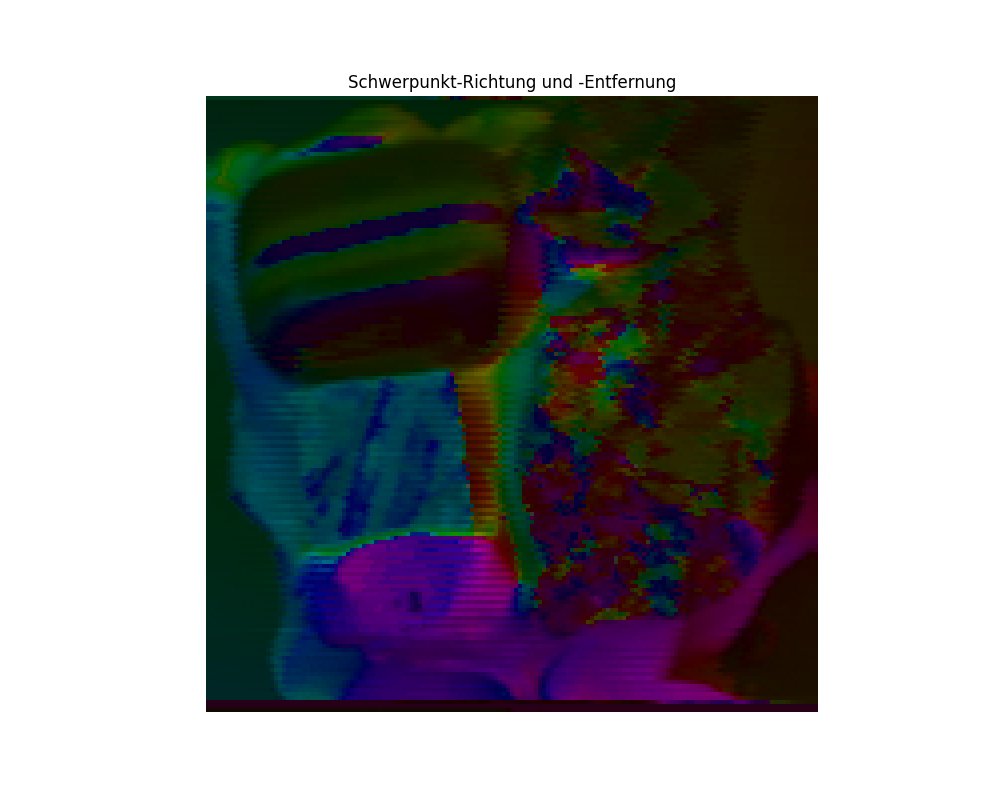

In [68]:
show_features(laserFlexData.output.getImageFeatures(), np.mean(laserFlexData.output.getImageColors(),axis=2))

In [58]:
np.mean(laserFlexData.output.getImageColors(),axis=2).astype(np.uint8)

array([[52, 52, 52, ..., 32, 32, 32],
       [35, 35, 35, ..., 32, 33, 33],
       [35, 35, 35, ..., 33, 33, 33],
       ...,
       [38, 38, 38, ..., 29, 29, 29],
       [38, 38, 38, ..., 37, 37, 37],
       [20, 20, 20, ..., 37, 37, 37]], dtype=uint8)